In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
import glob
import seaborn as sns

In [2]:
sns.set_theme(style="whitegrid")

<h1>Inicialização</h1>

In [ ]:
# Inicializando tabela geral
arquivos = glob.glob("./data/ticket_data/*.csv")
tabela = [pd.read_csv(arquivo) for arquivo in arquivos]
tabela = pd.concat(tabela, ignore_index=True)
tabela = tabela.drop(["fare_type", "vehicle_number", "integration_flag", "debited_amount", "anon_user_id"], axis=1)
tabela["transaction_date"] = pd.to_datetime(tabela["transaction_date"])

In [ ]:
# Inicializando tabela de chuva
chuva = pd.read_csv("./data/auxiliar_data/meteorological_data.csv")
chuva = chuva[["Timestamp (UTC)", "Wind Speed (m/s)", "Rain (mm)"]]
chuva["Timestamp (UTC)"] = pd.to_datetime(chuva["Timestamp (UTC)"])

In [ ]:
# Fazemos o merge das tabelas
tabela = tabela.reset_index()
tabela['dia'] = tabela["transaction_date"].dt.date
tabela['hora'] = tabela["transaction_date"].dt.hour

chuva['dia'] = chuva['Timestamp (UTC)'].dt.date
chuva['hora'] = chuva['Timestamp (UTC)'].dt.hour

tabela = tabela.merge(
    chuva[['dia', 'hora', 'Rain (mm)']], 
    on=['dia', 'hora'], 
    how='left'
)

tabela = tabela.drop(columns=['dia', 'hora'])

# Interpolamos os dados com NaN
tabela["Rain (mm)"] = tabela["Rain (mm)"].interpolate(method="linear")

In [ ]:
tabela

In [ ]:
tabela[tabela.duplicated()==True]

<h1>Estudo geral de dados</h1>

In [ ]:
# Maioria dos dados em dia de semana (dados insuficientes nos finais de semana)
tabela.groupby("day_type").agg({"transaction_date":"count"})

In [9]:
# Trabalharemos somente com dias da semana
tabela = tabela[tabela["day_type"] == 1]

In [ ]:
tabela.groupby("card_type").agg({"transaction_date":"count"})

In [11]:
# Separamos por hora
resumo = tabela.groupby([tabela["transaction_date"].dt.floor('H')]).agg({
    'transaction_date': 'count'   # Quantidade de pessoas/transações
}).rename(columns={'transaction_date': 'qtd_pessoas'})

In [ ]:
# Fazemos o merge das tabelas
resumo = resumo.reset_index()
resumo['dia'] = resumo["transaction_date"].dt.date
resumo['hora'] = resumo["transaction_date"].dt.hour

resumo = resumo.merge(
    chuva[['dia', 'hora', 'Rain (mm)']], 
    on=['dia', 'hora'], 
    how='left'
)

resumo = resumo.drop(columns=['dia', 'hora'])

# Interpolamos os dados com NaN
resumo["Rain (mm)"] = resumo["Rain (mm)"].interpolate(method="linear")

In [ ]:
resumo

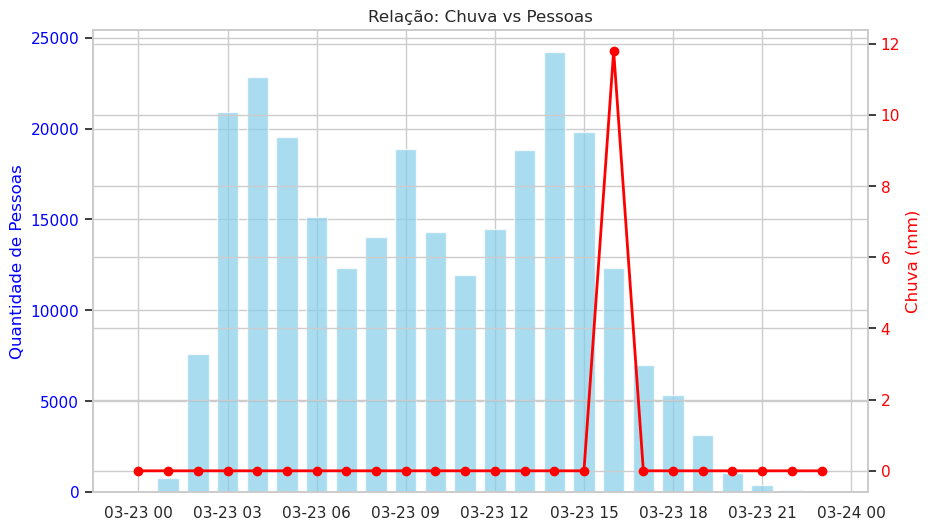

In [ ]:
# Plotamos o gráfico do dia com mais chuva
semana = resumo[(resumo["transaction_date"].dt.day == 23)]

fig, ax1 = plt.subplots(figsize=(10, 6))

# Quantidade de Pessoas (Barras)
ax1.bar(semana["transaction_date"], semana['qtd_pessoas'], color='skyblue', label='Qtd Pessoas', alpha=0.7, width=0.03)
ax1.set_ylabel('Quantidade de Pessoas', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Chuva (Linha)
ax2 = ax1.twinx() 
ax2.plot(semana["transaction_date"], semana['Rain (mm)'], color='red', marker='o', linewidth=2, label='Chuva (mm)')
ax2.set_ylabel('Chuva (mm)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

plt.title('Relação: Chuva vs Pessoas')
plt.show()

In [ ]:
semana

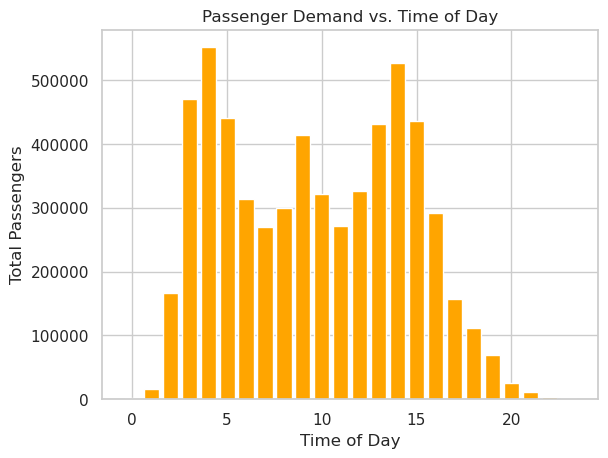

In [ ]:
# soma todas as pessoas que passaram às 08h, 09h, 10h... juntando todos os dias
por_hora = resumo.groupby(resumo["transaction_date"].dt.hour).agg({'qtd_pessoas': 'sum'}).reset_index()

# Niterói é uma cidade com um fluxo massivo de pessoas que se deslocam para trabalhar no Rio de Janeiro.
# Esse horário coincide exatamente com a abertura e o pico do movimento das Barcas, o fluxo pesado na
# Ponte Rio-Niterói e os ônibus intermunicipais.

plt.bar(por_hora["transaction_date"], por_hora['qtd_pessoas'], color='orange')
plt.xlabel("Time of Day")
plt.ylabel("Total Passengers") 
plt.title("Passenger Demand vs. Time of Day")

plt.savefig("demanda_tempo.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
por_hora

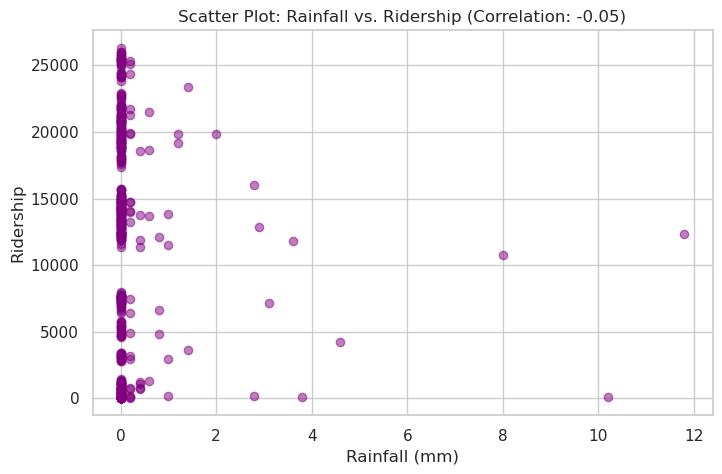

In [18]:
# Calcula a correlação entre as duas colunas
correlacao = resumo['qtd_pessoas'].corr(resumo['Rain (mm)'])

plt.figure(figsize=(8, 5))
plt.scatter(resumo['Rain (mm)'], resumo['qtd_pessoas'], alpha=0.5, color='purple')
plt.title(f'Scatter Plot: Rainfall vs. Ridership (Correlation: {correlacao:.2f})')
plt.xlabel('Rainfall (mm)')
plt.ylabel('Ridership')
plt.savefig("dispersao.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [19]:
# Teste de hipótese
amostra_seca = resumo[resumo["Rain (mm)"]<2.5]
amostra_chuva = resumo[resumo["Rain (mm)"]>=2.5]

In [ ]:
amostra_seca

In [ ]:
amostra_chuva

In [22]:
# p-valor insuficiente
t_stat, p_valor = stats.ttest_ind(amostra_seca["qtd_pessoas"], amostra_chuva["qtd_pessoas"], equal_var=False)
print(p_valor)

0.08730556993453362


<h1>Uso de estações geral</h1>

In [ ]:
# Cria a data pura (sem horas)
tabela["data_pura"] = pd.to_datetime(tabela["transaction_date"]).dt.date

# Descobre a chuva máxima registrada em cada dia
chuva_por_dia = tabela.groupby("data_pura")["Rain (mm)"].max().reset_index()

# Classifica o DIA INTEIRO como Seco ou Chuva
chuva_por_dia["clima_do_dia"] = np.where(
    chuva_por_dia["Rain (mm)"] < 2.5, "Seco", "Chuva"
)

# Remove a classificação antiga e traz a nova classificação do dia para a tabela
tabela = tabela.drop(columns=["clima"], errors="ignore")
tabela = tabela.merge(
    chuva_por_dia[["data_pura", "clima_do_dia"]], on="data_pura", how="left"
)

# agrupamos o volume diário pelo clima real do dia inteiro
volume_diario_estacao = (
    tabela.groupby(["clima_do_dia", "data_pura", "view_type"])
    .size()
    .reset_index(name="total_pessoas")
)

# Tira a média diária de transações por tipo de clima do dia
medias_estacao = (
    volume_diario_estacao.groupby(["view_type", "clima_do_dia"])["total_pessoas"]
    .mean()
    .unstack(fill_value=0)
)

# Calcula a variação percentual real
medias_estacao["variacao_pct"] = (
    (medias_estacao["Chuva"] - medias_estacao["Seco"]) / medias_estacao["Seco"]
) * 100

# Ordena pelo impacto real da chuva
ranking_real = medias_estacao.sort_values(by="variacao_pct")

print(ranking_real)

In [44]:
def calcular_cohen_d(g1, g2):
    # Médias
    m1, m2 = np.mean(g1), np.mean(g2)
    
    # Tamanhos das amostras
    n1, n2 = len(g1), len(g2)
    
    # Variâncias
    v1, v2 = np.var(g1, ddof=1), np.var(g2, ddof=1)
    
    # Desvio padrão agrupado (Pooled Standard Deviation)
    sd_pooled = np.sqrt(((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2))
    
    # Retorna o d de Cohen
    return abs((m1 - m2) / sd_pooled)

In [ ]:
resultados_testes = []

# testa cada linha individualmente
for linha in volume_diario_estacao["view_type"].unique():
    dados_linha = volume_diario_estacao[volume_diario_estacao["view_type"] == linha]
    
    # Separa em Seco/Chuva
    grupo_seco = dados_linha[dados_linha["clima_do_dia"] == "Seco"]["total_pessoas"]
    grupo_chuva = dados_linha[dados_linha["clima_do_dia"] == "Chuva"]["total_pessoas"]
    cohen = calcular_cohen_d(grupo_seco, grupo_chuva)
    
    # O teste precisa de pelo menos 2 dias de dados em cada grupo para rodar
    if len(grupo_seco) > 1 and len(grupo_chuva) > 1:
        # Aplica o Teste T de Welch
        t_stat, p_valor = stats.ttest_ind(grupo_seco, grupo_chuva, equal_var=False)
        
        resultados_testes.append({
            "view_type": linha,
            "t_stat": t_stat,
            "p_valor": p_valor,
            "cohen": cohen,
            "significativo_95%": "Sim" if p_valor < 0.05 else "Não"
        })

df_testes = pd.DataFrame(resultados_testes)

medias_resgata = medias_estacao.reset_index()
ranking_final = pd.merge(medias_resgata, df_testes, on="view_type")

ranking_final = ranking_final.sort_values(by="variacao_pct")

print(ranking_final[(ranking_final["significativo_95%"] == "Sim") | (ranking_final["p_valor"] <= 0.05)][["view_type", "variacao_pct", "p_valor", "significativo_95%", "cohen"]])

                                view_type  variacao_pct   p_valor  \
1                    BALDEADOR - CHARITAS    -13.115877  0.013175   
34                         MARTINS TORRES     25.536486  0.043818   
22  ITAIPU - CENTRO (VIA ENGENHO DO MATO)     26.046054  0.041803   
46                    SANTA ROSA - CENTRO     26.337865  0.040513   
16                       CUBANGO - CENTRO     26.562377  0.039486   
13               CENTRO X MORRO DO CASTRO     26.914988  0.038332   
40        PIRATININGA X CENTRO (VIA BHLS)     27.335743  0.038420   
47                          SAPE - CENTRO     27.708197  0.041537   
11                           CANTO DO RIO     28.820544  0.036030   
24   ITAIPU X CENTRO - (VIA PRAIA ICARAÍ)     30.640609  0.022918   
26                      ITITIOCA - CENTRO     31.822341  0.014897   

   significativo_95%     cohen  
1                Sim  1.173438  
34               Sim  0.500882  
22               Sim  0.511607  
46               Sim  0.516821  
16    

/tmp/ipykernel_20148/841113650.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


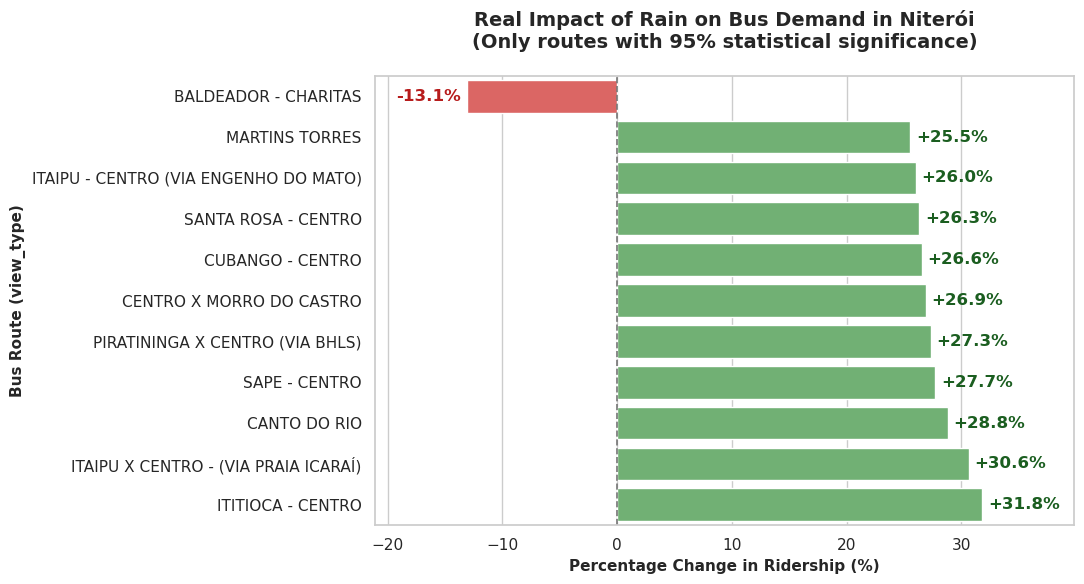

In [ ]:
linhas_significativas = ranking_final[ranking_final["p_valor"] <= 0.05].sort_values(
    by="variacao_pct"
)

plt.figure(figsize=(11, 6))
sns.set_theme(style="whitegrid")

cores = [
    "#ef5350" if x < 0 else "#66bb6a"
    for x in linhas_significativas["variacao_pct"]
]

ax = sns.barplot(
    x="variacao_pct", y="view_type", data=linhas_significativas, palette=cores
)

plt.axvline(0, color="#757575", linestyle="--", linewidth=1.2)

plt.title(
    "Real Impact of Rain on Bus Demand in Niterói\n(Only routes with 95% statistical significance)",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Percentage Change in Ridership (%)", fontsize=11, fontweight="bold")
plt.ylabel("Bus Route (view_type)", fontsize=11, fontweight="bold")

for i, v in enumerate(linhas_significativas["variacao_pct"]):
    if v < 0:
        ax.text(
            v - 0.5,
            i,
            f"{v:.1f}%",
            va="center",
            ha="right",
            fontweight="bold",
            color="#b71c1c",
        )
    else:
        ax.text(
            v + 0.5,
            i,
            f"+{v:.1f}%",
            va="center",
            ha="left",
            fontweight="bold",
            color="#1b5e20",
        )

plt.xlim(
    linhas_significativas["variacao_pct"].min() - 8,
    linhas_significativas["variacao_pct"].max() + 8,
)

plt.tight_layout()
plt.savefig("estacoes.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [26]:
estacoes = ranking_final[(ranking_final["significativo_95%"] == "Sim") | (ranking_final["p_valor"] <= 0.05)][["view_type", "variacao_pct", "p_valor", "significativo_95%"]]
estacoes = estacoes.reset_index().drop(["index", "p_valor", "significativo_95%"], axis=1)
estacoes["impacto"] = np.where(
    estacoes["variacao_pct"] < 0, "Negativo", "Positivo"
)
estacoes.to_csv("estacoes.csv", index=False)
print(estacoes)

                                view_type  variacao_pct   impacto
0                    BALDEADOR - CHARITAS    -13.115877  Negativo
1                          MARTINS TORRES     25.536486  Positivo
2   ITAIPU - CENTRO (VIA ENGENHO DO MATO)     26.046054  Positivo
3                     SANTA ROSA - CENTRO     26.337865  Positivo
4                        CUBANGO - CENTRO     26.562377  Positivo
5                CENTRO X MORRO DO CASTRO     26.914988  Positivo
6         PIRATININGA X CENTRO (VIA BHLS)     27.335743  Positivo
7                           SAPE - CENTRO     27.708197  Positivo
8                            CANTO DO RIO     28.820544  Positivo
9    ITAIPU X CENTRO - (VIA PRAIA ICARAÍ)     30.640609  Positivo
10                      ITITIOCA - CENTRO     31.822341  Positivo


In [49]:
df_testes.sort_values(by="cohen", ascending=False)

,view_type,t_stat,p_valor,cohen,significativo_95%
1,BALDEADOR - CHARITAS,2.966069,0.013175,1.173438,Sim
47,SAPE - PIRATININGA,1.451031,0.213620,1.133730,Não
30,LARGO BATALHA - CUBANGO,2.148541,0.067161,1.020442,Não
18,FONSECA - CENTRO,1.679432,0.144284,0.916521,Não
52,VENDA DA CRUZ - CENTRO VIA BENJAMIN CONSTANT,1.471433,0.194340,0.839427,Não
19,ILHA DA CONCEIÇÃO - CENTRO,1.860918,0.099560,0.837326,Não
43,RJ 106 X CENTRO,-1.122810,0.314519,0.772758,Não
31,LARGO DO MOURA - CENTRO,1.172700,0.292304,0.738765,Não
25,ITITIOCA - CENTRO,-2.632445,0.014897,0.627825,Sim
11,CANTO DO RIO,-2.225464,0.036030,0.603519,Sim
